### Task 3: Numerical Accuracy of the Solver

To investigate the accuracy of SciPy's `solve_ivp`, we used the logistic equation \(f'=f(1-f)\), which has a known exact solution. We selected an initial condition of \(f(0)=0.2\) and a final time of \(t=5\).

We calculated numerical solutions using different relative tolerances (`rtol`) ranging from \(10^{-3}\) to \(10^{-10}\), while keeping the absolute tolerance (`atol`) constant at \(10^{-12}\). We then compared each numerical solution with the exact solution at \(t=5\) to calculate its absolute error.

The results show that **decreasing the relative tolerance generally decreases the numerical error**, producing a more accurate approximation. However, smaller tolerances require the solver to take more steps, increasing computational effort.

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Implementing logistic differential equation
def logistic(t, f):
    return f * (1 - f)

# Implimenting known exact solution equation
def exact(t, f0):
    return 1 / (1 + ((1 - f0) / f0) * np.exp(-t))

# Defining initial conditions
f0 = 0.2
t_span = (0, 5)

In [ ]:

# Generates 8 log values evenly spaced between 10^{-3} and 10^{-10}
rtol_values = np.logspace(-3, -10, 8)

# Generates an empty list
errors = []

# Creates a for loop
for rtol in rtol_values:

    # function for generating a solution using solve_ivp
    # logistic is the function for the Logistic Equation
    # t_span is the time interval from 0 to 5
    # [f0] is the initial population, which we defined as being = 0.2
    # rtol determines how precise the calculated values must be
    # atol is a fixed level of absolute tolerance which we can compare with the changing values of rtol
    sol = solve_ivp(logistic, t_span, [f0], rtol=rtol, atol=1e-12)

    # Calculates the solution using solve_ivp at t = 5
    numerical = sol.y[0, -1]

    # Calculates the solution using the manually derived exact solution formula at t = 5
    actual = exact(5, f0)

    # Calculates absolute error
    error = abs(numerical - actual)

    # Appends each absolute error value to a list
    errors.append(error)

    # Prints each rtol value with its corresponding absolute error value
    print(f"rtol = {rtol:.0e}, Error = {error:.3e}")


rtol = 1e-03, Error = 6.519e-05
rtol = 1e-04, Error = 4.805e-06
rtol = 1e-05, Error = 1.207e-07
rtol = 1e-06, Error = 4.919e-08
rtol = 1e-07, Error = 8.717e-09
rtol = 1e-08, Error = 1.210e-09
rtol = 1e-09, Error = 1.439e-10
rtol = 1e-10, Error = 1.576e-11


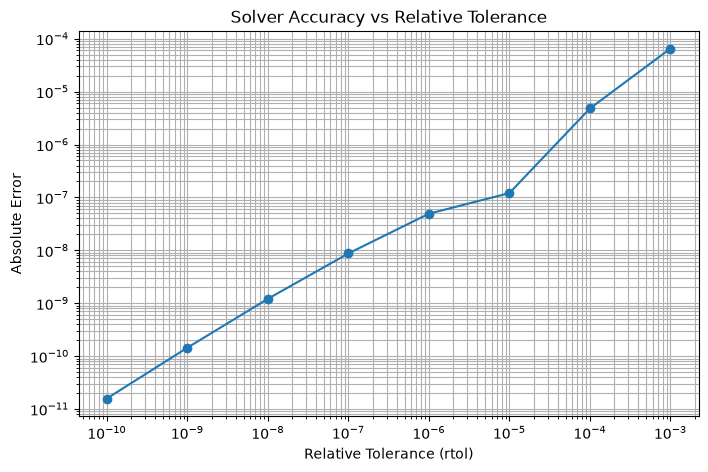

In [ ]:
# Creating log-log graph for each absolute error value at each rtol value
plt.figure(figsize=(8, 5))

plt.loglog(rtol_values, errors, marker='o')

plt.xlabel('Relative Tolerance (rtol)')
plt.ylabel('Absolute Error')
plt.title('Solver Accuracy vs Relative Tolerance')

plt.grid(True, which='both')
plt.show()
